In [2]:
!pip -q install -U datasets huggingface_hub


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
pd.set_option('display.max_colwidth', None)   
pd.set_option('display.max_columns', None)    
pd.set_option('display.width', None)          


In [4]:
hc3 = pd.read_json("hf://datasets/Hello-SimpleAI/HC3/all.jsonl", lines=True)


/Users/ngokykhanhthu/summer26/chewy/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
hc3.head(5)

,question,human_answers,chatgpt_answers,index,source
0,"Why is every book I hear about a "" NY Times # ...","[Basically there are many categories of "" Best...",[There are many different best seller lists th...,NaN,reddit_eli5
1,"If salt is so bad for cars , why do we use it ...",[salt is good for not dying in car crashes and...,[Salt is used on roads to help melt ice and sn...,NaN,reddit_eli5
2,Why do we still have SD TV channels when HD lo...,[The way it works is that old TV stations got ...,[There are a few reasons why we still have SD ...,NaN,reddit_eli5
3,Why has nobody assassinated Kim Jong - un He i...,[You ca n't just go around assassinating the l...,[It is generally not acceptable or ethical to ...,NaN,reddit_eli5
4,How was airplane technology able to advance so...,[Wanting to kill the shit out of Germans drive...,[After the Wright Brothers made the first powe...,NaN,reddit_eli5


In [6]:
hc3['index'].value_counts()

index
0.0       1
4163.0    1
4156.0    1
4157.0    1
4158.0    1
         ..
841.0     1
842.0     1
843.0     1
844.0     1
4999.0    1
Name: count, Length: 2521, dtype: int64

In [7]:
hc3_no_idx = hc3.drop('index', axis=1)

In [8]:
hc3_no_idx.columns.to_list()

['question', 'human_answers', 'chatgpt_answers', 'source']

In [9]:
hc3_no_idx['source'].value_counts()

source
reddit_eli5    17112
finance         3933
medicine        1248
open_qa         1187
wiki_csai        842
Name: count, dtype: int64

In [10]:
hc3_no_idx['question'].nunique()

23492

In [11]:
hc3_no_idx.isna().sum()

question           0
human_answers      0
chatgpt_answers    0
source             0
dtype: int64

In [12]:
# human_counts_v = hc3_no_idx['human_answers'].apply(lambda x: len(x[0].split()))

In [13]:
# sns.histplot(data=human_counts_v)

# FINALISED CHANGES 

dropped index 

no na

dropped those with <=1 word for either human or chatgpt 

dropped row where word count of human response > 2600 words 

pending: 458 rows with no chatgpt responses

In [14]:
hc3_no_idx.columns.to_list()

['question', 'human_answers', 'chatgpt_answers', 'source']

In [19]:
hc3_no_idx["human_word_count"] = hc3_no_idx["human_answers"].apply(lambda x: len(x[0].split()) if len(x) > 0 else 0)
hc3_no_idx["chatgpt_word_count"] = hc3_no_idx["chatgpt_answers"].apply(lambda x: len(x[0].split()) if len(x) > 0 else 0)


In [23]:

print("Human answers with <=1 word:", (hc3_no_idx["human_word_count"] <= 1).sum()*100/hc3_no_idx.shape[0])
print("ChatGPT answers with <=1 word:", (hc3_no_idx["chatgpt_word_count"] <= 1).sum()*100/hc3_no_idx.shape[0])

Human answers with <=1 word: 0.004111503988158869
ChatGPT answers with <=1 word: 1.883068826576762


In [39]:
(hc3_no_idx["chatgpt_word_count"] <= 1).sum()

np.int64(458)

rows that either don't have a human answer or a chatgpt answer or both together
make up a small percentage, so we should drop them

In [26]:
hc3_no_idx[hc3_no_idx["human_word_count"] <=1]

,question,human_answers,chatgpt_answers,source,human_word_count,chatgpt_word_count
23177,"Pressure in temple, whooshing sensation. Is it related to stress or anxiety?I have this weird whooshing feeling in my left temple. Like, a little bit of pressure all the time, but every once in a while it speeds up to a whoosh like bugs or something are crawling outwards from the temple. It doesn t hurt, it just feels really weird. If it s just stress or anxiety then so be it. Just concerned it might be something more.",[Hello],"[It is possible that the sensation you are experiencing in your temple could be related to stress or anxiety. Stress and anxiety can cause a range of physical symptoms, including sensation changes in the head and face. Other factors that can contribute to sensations like these include fatigue, tension headaches, sinus problems, and eyestrain.\n\nIt is always a good idea to speak with a healthcare provider if you are concerned about your physical symptoms, especially if they are persistent or interfere with your daily activities. They can help determine the cause of your symptoms and recommend appropriate treatment. In the meantime, it may be helpful to try some stress-reducing techniques, such as deep breathing, progressive muscle relaxation, or exercise, to see if that helps alleviate the sensation., !\nToo many requests in 1 hour. Try again later.\n\n\n\nThere was an error generating a response, It is possible that the pressure and whooshing sensation in your temple could be related to stress or anxiety. Stress and anxiety can cause a variety of physical symptoms, including changes in blood pressure, heart rate, and blood flow, which can affect the sensation in different parts of the body.\n\nHowever, it is important to note that these symptoms could also be caused by other factors, such as certain medications, eye strain, or sinus issues. If you are concerned about the sensation in your temple, it is always a good idea to speak with a healthcare professional for a proper evaluation and diagnosis. They can help determine the cause of your symptoms and recommend the appropriate treatment.]",medicine,1,127


# TODO: OPTIONALLY FILL UP THE EMPTY CHATGPT ONES BY JUST GENERATING THE RESPONSES YOURSELF BY PROMPTING GPT 3 

In [28]:
hc3_no_idx[hc3_no_idx["chatgpt_word_count"] <=1]

,question,human_answers,chatgpt_answers,source,human_word_count,chatgpt_word_count
8172,How is soil formed ? Is there soil on moon?If yes how it was formed ? Explain like I'm five.,"[Does n't soil consist of a number of different materials other than rocks ? It also contains a number of decomposed plant and sometimes animal matter , if I 'm correct ., Soil is formed by mechanical breaking up of rocks . All soil is is just tiny little particles of rock and organic compounds . The moon does have some soil but it is more of a fine dust . There is no wind to blow the dust away so it settles on the surface . It is formed by asteroids and other collisions ., You break a rock , you get smaller rocks . Break that , and you get even smaller rocks . Repeat until you have soil .]",[],reddit_eli5,32,0
8173,What is earwax and why do we have it ? I was just cleaning my headphones and I wondered what earwax was and why we have it . Thanks for the answers ! Explain like I'm five.,"[What is it ? Not sure what the chemical composition is but is serves the same function as snot ... it 's there to trap and assist to expel dirt and other ' gunk ' from your ears . Now you might say ' but it IS gunk ' . Yes it is ... but it 's good gunk made by your body to get rid of bad gunk ., It 's quite literally a wax produced by the ears . It protects the ear canal from infection ., It 's like boogers in your nose . Dust and bugs fly in , your body deal with them by incasing them in goo . In your nose it 's mucus that can either be runny ( need a tissue ) or harden ( need to be picked at ) . In your ear , it 's a waxy substance that should be cleared out with q - tips ( be careful , sticking things in your ear is n't always a good idea , so go easy ) . Earwax itself is n't particularly special . It 's made up of the same stuff as your fingernails , plus some fat , oils , and alcohol for good measure . If you 've never had your ears professionally cleaned out , you should try it one day ! As best as I can describe it , it 's a bit painful , but you feel incredible afterward , plus you can hear a lot more !]",[],reddit_eli5,70,0
8438,"Why is it that Jalapeño is spelt with a "" J "" producing the sound of an english "" H "" while Habanero is just spelled with an H ? Explain like I 'm Cinco . Explain like I'm five.","[Because Spanish orthography has rules that differ from those used by English . J is pronounced in various ways depending on country , but something like an h or the ch in loch is common . H is silent ., H is silent in spanish , although pronouncing it does n't make words sound all that different . But pronouncing a Spanish word with an English j makes it sound funny , so we do n't do that ..., J is not pronounced like an H , it is pronounced like a CH as in : URL_1 or URL_0]",[],reddit_eli5,40,0
8439,What is the difference between mexican soda and U.S. soda what is the difference between mexican soda and U.S. soda . Recently I saw an article that mexican coke was switching to high fructose syrup from cane sugar and I did n't know the difference between mexican and U.S. Explain like I'm five.,"[Soda made in the U.S. has been made from high fructose corn syrup ( HFCS ) for decades . Soda made in many other parts of the world continued to be made with cane sugar ( and in glass bottles ) . The difference is in the taste . If you do n't believe me , seek out your most Latin neighborhood and find an abnormally tall glass bottle of Coke , Sprite , or Fanta . Then thank me for changing your life . Also , assuming you 're anywhere in the southern half of the country , they sell this stuff in bulk at your local home depot ., In the US you have both subsidies for domestic corn growers and tariffs against foreign sugar imports which means we drink the crap stuff ., That 's the main difference . They use cane sugar instead of HFCS . HFCS is cheaper in the US , so many products are sweetened with it instead of cane sugar .]",[],reddit_eli5,111,0
8681,How is soil 

In [34]:
hc3_symm = hc3_no_idx[(hc3_no_idx["chatgpt_word_count"] >1) & (hc3_no_idx["human_word_count"] >1)]

In [35]:
hc3_no_idx.shape

(24322, 6)

In [36]:
hc3_symm.shape

(23863, 6)

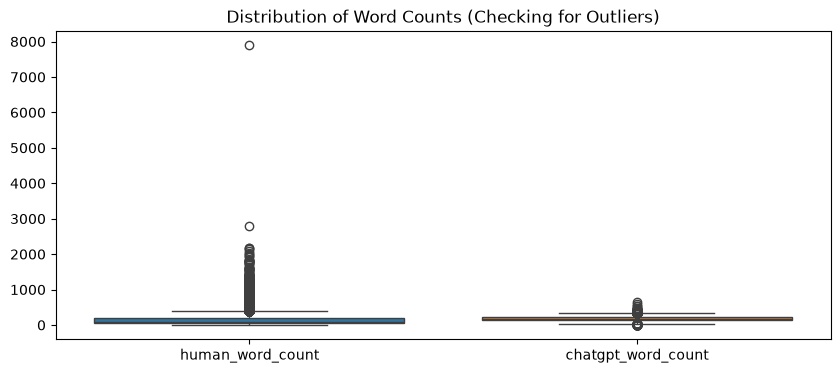

In [42]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=hc3_symm[["human_word_count", "chatgpt_word_count"]])
plt.title("Distribution of Word Counts (Checking for Outliers)")
plt.show()

In [43]:
hc3_symm[hc3_symm['human_word_count'] > 7000]

question  \
15050  What exactly is Obamacare and what did it change ? I understand what medicare is and everything but I 'm not sure what Obamacare changed . Explain like I'm five.   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

In [46]:
hc3_no_outlier = hc3_symm[hc3_symm['human_word_count'] <2600]

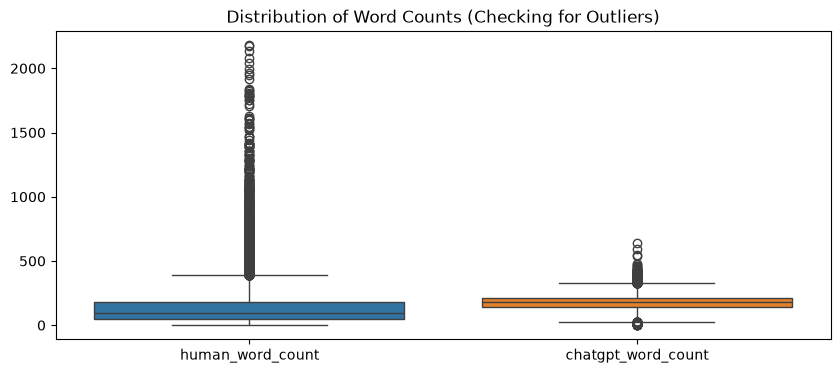

In [48]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=hc3_no_outlier[["human_word_count", "chatgpt_word_count"]])
plt.title("Distribution of Word Counts (Checking for Outliers)")
plt.show()

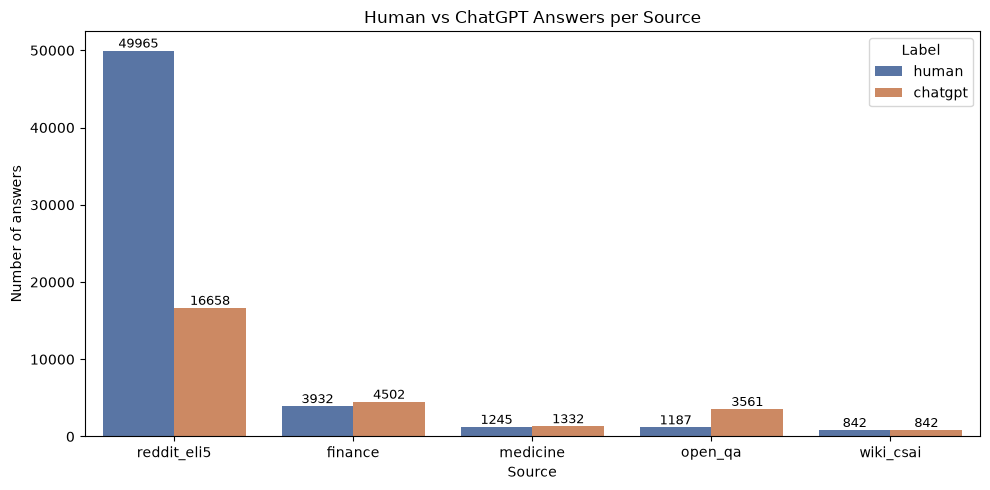

,human,chatgpt
source,,
reddit_eli5,49965,16658
finance,3932,4502
medicine,1245,1332
open_qa,1187,3561
wiki_csai,842,842


In [49]:
# Count individual answers (each row holds lists of answers)
label_counts = (
    hc3_no_outlier
    .assign(
        human=hc3_no_outlier["human_answers"].apply(len),
        chatgpt=hc3_no_outlier["chatgpt_answers"].apply(len),
    )
    .groupby("source")[["human", "chatgpt"]]
    .sum()
    .sort_values("human", ascending=False)
)

# Long format for seaborn
label_long = (
    label_counts
    .reset_index()
    .melt(id_vars="source", var_name="label", value_name="count")
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=label_long, x="source", y="count", hue="label",
                 palette={"human": "#4C72B0", "chatgpt": "#DD8452"})
for container in ax.containers:
    ax.bar_label(container, fmt="%d", fontsize=9)
plt.title("Human vs ChatGPT Answers per Source")
plt.xlabel("Source")
plt.ylabel("Number of answers")
plt.legend(title="Label")
plt.tight_layout()
plt.show()

label_counts
